# AI Data Center Power and Cooling Load Forecasting

**Goal:** forecast the hourly IT load, the cooling power and the Power Usage Effectiveness (PUE) of a data center for the next 7 days, and compare classical time-series models (Seasonal Naive, ARIMAX) with a machine learning model (Random Forest).

**Data:** real hourly outdoor temperature and humidity for Cairo (Open-Meteo archive; a synthetic fallback is used if the API is offline) and a simulated IT load with daily and weekly cycles, slow growth and AI training bursts. Cooling power is derived from the IT load and the outdoor temperature.

**Structure:** the same steps as the lab notebook (Setup, Data, Trend, Seasonality, ACF, Stationarity, Differencing, Train/Test split, Models, Evaluation, Residuals, Forecast, Conclusions), followed by the student improvements.

**Markers used in every cell**

> **[LAB REQUIREMENT]** = part of the structure required by the lab.

> **[STUDENT IMPROVEMENT]** = extra work added by the student beyond the lab.

**How to run:** `pip install numpy pandas matplotlib statsmodels scikit-learn requests`, then run all cells. Internet is only needed for the real weather data.

## 1. Setup
> **[LAB REQUIREMENT]**

In [1]:
# [LAB REQUIREMENT]
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Data

**Weather** (real data for Cairo, Egypt, hourly, 2024-07-01 to 2025-06-30)
> **[STUDENT IMPROVEMENT]**

In [2]:
# [STUDENT IMPROVEMENT]
LAT, LON = 30.0444, 31.2357          # Cairo, Egypt
START, END = "2024-07-01", "2025-06-30"
N_HOURS = 365 * 24                    # 8760 hourly records


def fetch_weather(lat, lon, start, end):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "hourly": "temperature_2m,relative_humidity_2m",
        "timezone": "GMT",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    h = r.json()["hourly"]
    return pd.DataFrame(
        {"temp_c": h["temperature_2m"], "rh": h["relative_humidity_2m"]},
        index=pd.to_datetime(h["time"]),
    )


try:
    weather = fetch_weather(LAT, LON, START, END)
    weather_source = "Open-Meteo archive (real data)"
except Exception as e:
    print("Weather API not available, using synthetic weather. Reason:", e)
    idx_fb = pd.date_range(START, periods=N_HOURS, freq="h")
    doy, hr = idx_fb.dayofyear.values, idx_fb.hour.values
    temp = 24 + 8 * np.sin(2 * np.pi * (doy - 110) / 365) + 4 * np.sin(2 * np.pi * (hr - 14) / 24)
    temp = temp + np.random.normal(0, 1.5, len(idx_fb))
    rh = np.clip(55 - 1.2 * (temp - 24) + np.random.normal(0, 5, len(idx_fb)), 10, 100)
    weather = pd.DataFrame({"temp_c": temp, "rh": rh}, index=idx_fb)
    weather_source = "synthetic fallback"

weather = weather.asfreq("h")
print("Weather source:", weather_source, "| rows:", len(weather))
weather.head()

Weather source: Open-Meteo archive (real data) | rows: 8760


,temp_c,rh
2024-07-01 00:00:00,25.7,70
2024-07-01 01:00:00,25.0,69
2024-07-01 02:00:00,24.3,74
2024-07-01 03:00:00,23.8,78
2024-07-01 04:00:00,25.1,75


**IT load and cooling power** (simulated with physics-inspired rules, using the real temperature)
> **[STUDENT IMPROVEMENT]**

In [3]:
# [STUDENT IMPROVEMENT]
idx = weather.index
n = len(idx)
hours = idx.hour.values
dow = idx.dayofweek.values

# 1) IT load = base + daily cycle + weekend dip + slow capacity growth + noise
daily = 180 * np.sin(2 * np.pi * (hours - 9) / 24)
weekly = np.where(dow >= 5, -120.0, 0.0)
growth = np.linspace(0, 120, n)
noise = np.random.normal(0, 25, n)

# 2) AI training bursts: GPU jobs start suddenly and run for several hours
bursts = np.zeros(n)
on, level = False, 0.0
for t in range(n):
    if not on and np.random.rand() < 0.02:
        on, level = True, np.random.uniform(250, 450)
    elif on and np.random.rand() < 0.10:
        on = False
    bursts[t] = level if on else 0.0

it_kw = np.clip(1500 + daily + weekly + growth + bursts + noise, 400, None)

# 3) Cooling depends on IT load and on the outdoor temperature (with thermal inertia, EWM)
temp_ema3 = pd.Series(weather["temp_c"].values).ewm(span=3, adjust=False).mean().values
cool_factor = 0.14 + 0.007 * np.clip(temp_ema3 - 18, 0, None)
cooling_kw = np.clip(it_kw * cool_factor + np.random.normal(0, 15, n), 0, None)

# 4) Power distribution overhead (UPS, transformers) is about 5% of IT load
overhead_kw = 0.05 * it_kw + np.random.normal(0, 5, n)
total_kw = it_kw + cooling_kw + overhead_kw
pue = total_kw / it_kw

df = pd.DataFrame({
    "temp_c": weather["temp_c"].values,
    "rh": weather["rh"].values,
    "temp_ema3": temp_ema3,
    "it_kw": it_kw,
    "cooling_kw": cooling_kw,
    "total_kw": total_kw,
    "pue": pue,
}, index=idx).asfreq("h")

df.to_csv("datacenter_hourly_2024_2025.csv")
df.head()

,temp_c,rh,temp_ema3,it_kw,cooling_kw,total_kw,pue
2024-07-01 00:00:00,25.7,70,25.70000,1385.138633,279.438336,1731.905538,1.250348
2024-07-01 01:00:00,25.0,69,25.35000,1340.672520,252.377233,1662.171321,1.239804
2024-07-01 02:00:00,24.3,74,24.82500,1342.352965,230.510551,1639.725556,1.221531
2024-07-01 03:00:00,23.8,78,24.31250,1358.116847,258.414049,1685.429753,1.241005
2024-07-01 04:00:00,25.1,75,24.70625,1320.334318,228.744513,1611.586255,1.220590


**Data check** (shape, missing values, interpolation, summary)
> **[LAB REQUIREMENT]**

In [4]:
# [LAB REQUIREMENT]
print("Shape:", df.shape)
print("Period:", df.index.min(), "to", df.index.max())
print("Missing values per column:")
print(df.isna().sum())

df = df.interpolate(method="time")  # fill any gap by time
df.describe().round(2)

Shape: (8760, 7)
Period: 2024-07-01 00:00:00 to 2025-06-30 23:00:00
Missing values per column:
temp_c        0
rh            0
temp_ema3     0
it_kw         0
cooling_kw    0
total_kw      0
pue           0
dtype: int64


,temp_c,rh,temp_ema3,it_kw,cooling_kw,total_kw,pue
count,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00
mean,24.11,48.13,24.11,1582.88,301.49,1963.49,1.24
std,7.89,21.77,7.71,200.24,95.05,279.41,0.05
min,6.90,6.00,7.18,1153.49,137.16,1399.47,1.15
25%,17.90,30.00,17.99,1428.56,225.25,1734.97,1.20
50%,23.40,46.00,23.51,1567.52,277.76,1947.09,1.23
75%,29.80,66.00,29.74,1702.32,364.61,2140.50,1.27
max,43.80,100.00,43.15,2271.17,652.39,2996.63,1.38


**Sample week** (quick look at the data before modelling)
> **[STUDENT IMPROVEMENT]**

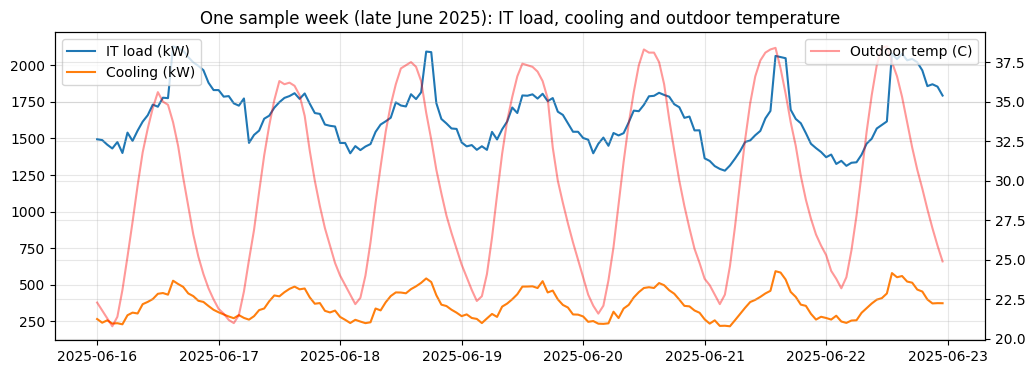

In [5]:
# [STUDENT IMPROVEMENT]
sample = df.loc["2025-06-16":"2025-06-22"]
fig, ax = plt.subplots()
ax.plot(sample["it_kw"], label="IT load (kW)")
ax.plot(sample["cooling_kw"], label="Cooling (kW)")
ax2 = ax.twinx()
ax2.plot(sample["temp_c"], color="red", alpha=0.4, label="Outdoor temp (C)")
ax.set_title("One sample week (late June 2025): IT load, cooling and outdoor temperature")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.show()

## 3. Trend
Moving averages on cooling power, as in the lab (5-year MA became 24h and 7-day MA here).
> **[LAB REQUIREMENT]**

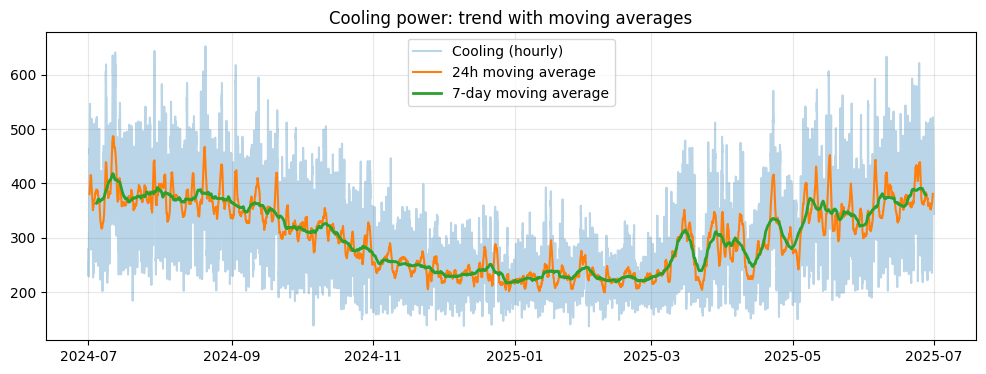

In [6]:
# [LAB REQUIREMENT]
ma24 = df["cooling_kw"].rolling(24, center=True).mean()
ma168 = df["cooling_kw"].rolling(168, center=True).mean()

fig, ax = plt.subplots()
ax.plot(df["cooling_kw"], alpha=0.3, label="Cooling (hourly)")
ax.plot(ma24, linewidth=1.5, label="24h moving average")
ax.plot(ma168, linewidth=2, label="7-day moving average")
ax.set_title("Cooling power: trend with moving averages")
ax.legend()
plt.show()

## 4. ACF (auto-correlation)
> **[LAB REQUIREMENT]**

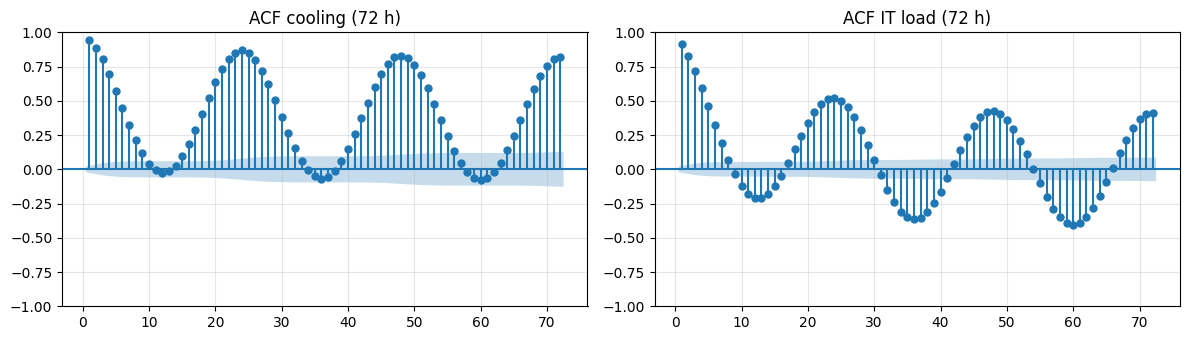

In [7]:
# [LAB REQUIREMENT]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(df["cooling_kw"], lags=72, zero=False, ax=ax[0]); ax[0].set_title("ACF cooling (72 h)")
plot_acf(df["it_kw"], lags=72, zero=False, ax=ax[1]); ax[1].set_title("ACF IT load (72 h)")
plt.tight_layout(); plt.show()

## 5. Seasonality (STL decomposition, period = 24 h)
> **[LAB REQUIREMENT]**

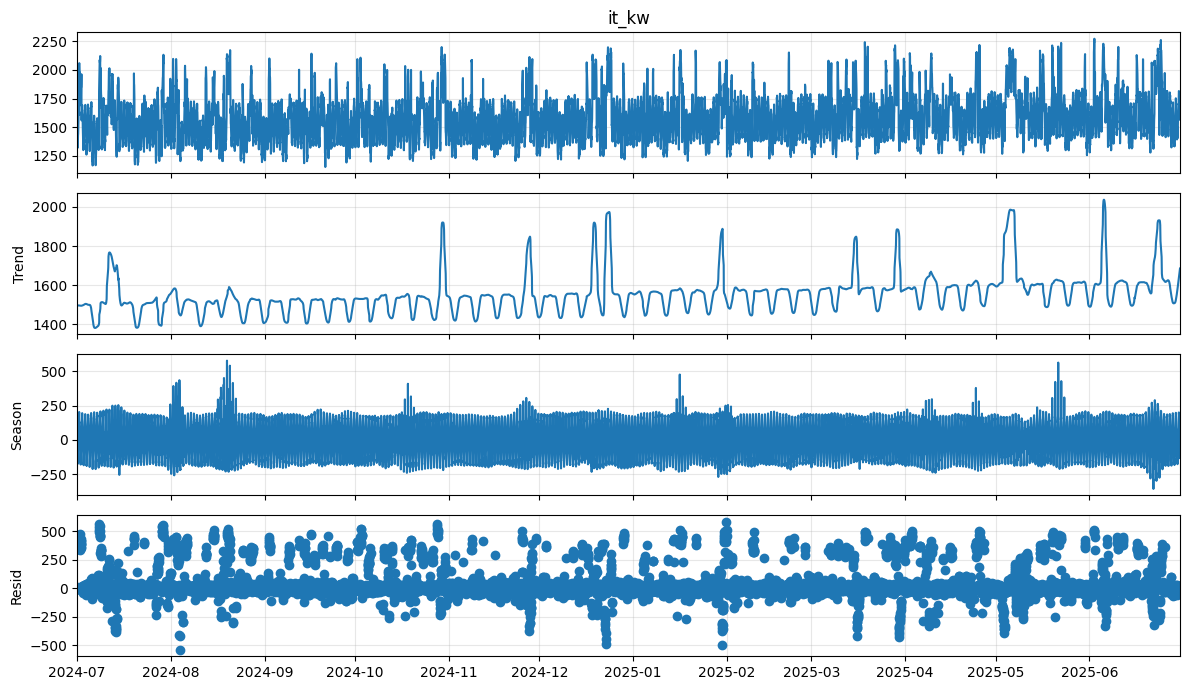

In [8]:
# [LAB REQUIREMENT]
stl = STL(df["it_kw"], period=24, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 7)
plt.tight_layout(); plt.show()

## 6. Stationarity (ADF + KPSS)
- ADF: H0 = non-stationary. If p < 0.05, the series is stationary.
- KPSS: H0 = stationary. If p < 0.05, the series is non-stationary.
> **[LAB REQUIREMENT]**

In [9]:
# [LAB REQUIREMENT]
def stationarity_report(series, name):
    s = series.dropna()
    adf_p = adfuller(s)[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    print(name)
    print(f"  ADF  p = {adf_p:.4f} -> {'stationary' if adf_p < .05 else 'non-stationary'}")
    print(f"  KPSS p = {kpss_p:.4f} -> {'non-stationary' if kpss_p < .05 else 'stationary'}")

stationarity_report(df["it_kw"], "IT load")
stationarity_report(df["cooling_kw"], "Cooling power")

/tmp/ipykernel_5320/3887876371.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]


IT load
  ADF  p = 0.0000 -> stationary
  KPSS p = 0.0100 -> non-stationary


Cooling power
  ADF  p = 0.0000 -> stationary
  KPSS p = 0.0100 -> non-stationary


/tmp/ipykernel_5320/3887876371.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]


## 7. ACF / PACF after differencing
A 24-hour seasonal difference removes the daily cycle. PACF cutting off suggests p, ACF cutting off suggests q.
> **[LAB REQUIREMENT]**

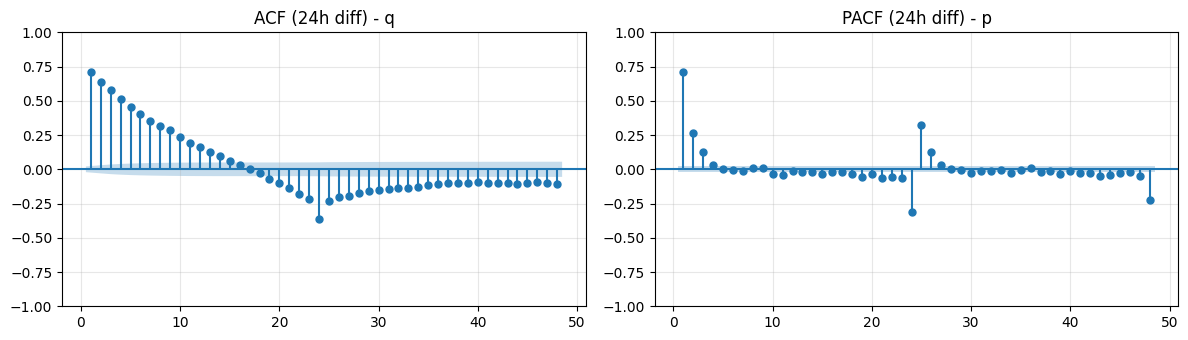

In [10]:
# [LAB REQUIREMENT]
diff24 = df["cooling_kw"].diff(24).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(diff24, lags=48, zero=False, ax=ax[0]); ax[0].set_title("ACF (24h diff) - q")
plot_pacf(diff24, lags=48, zero=False, method="ywm", ax=ax[1]); ax[1].set_title("PACF (24h diff) - p")
plt.tight_layout(); plt.show()

## 8. Train / Test split (by time)
The last 168 hours (7 days) are the test set. No shuffling, to avoid data leakage.
> **[LAB REQUIREMENT]**

In [11]:
# [LAB REQUIREMENT]
H = 168  # forecast horizon: 7 days (hourly)
train = df.iloc[:-H]
test = df.iloc[-H:]
print("Train:", len(train), "| Test:", len(test))
print("Test period:", test.index[0], "to", test.index[-1])

Train: 8592 | Test: 168
Test period: 2025-06-24 00:00:00 to 2025-06-30 23:00:00


## 9. Models

**Helpers and baseline**
- Seasonal Naive: predict the value of the same hour one day earlier (the lab's naive model, adapted to hourly data with a daily season).
> **[LAB REQUIREMENT]**

In [12]:
# [LAB REQUIREMENT]
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    return {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAPE %": np.mean(np.abs(err) / y_true) * 100,
    }

TARGETS = ["cooling_kw", "it_kw"]

**ARIMA family with exogenous variables.** Candidate orders are compared by AIC, as in the lab.
The daily and weekly cycles are modelled with Fourier terms (sin/cos pairs) and the outdoor temperature is an exogenous variable.
A full seasonal SARIMA with period 24 needs a very large state space and ran out of memory inside the notebook kernel, so the seasonality is handled with Fourier regressors instead (dynamic harmonic regression, a standard approach).
> **[LAB REQUIREMENT]**
> **[STUDENT IMPROVEMENT]** (Fourier seasonal terms and temperature as exogenous variables)

In [13]:
# [LAB REQUIREMENT] ARIMA candidates selected by AIC
# [STUDENT IMPROVEMENT] Fourier terms for the 24 h and 168 h cycles, plus outdoor temperature
T0 = df.index[0]


def make_exog(data):
    t = (data.index - T0) / pd.Timedelta(hours=1)
    ex = pd.DataFrame(index=data.index)
    for K in (1, 2, 3):
        ex[f"s24_{K}"] = np.sin(2 * np.pi * K * t / 24)
        ex[f"c24_{K}"] = np.cos(2 * np.pi * K * t / 24)
    for K in (1, 2):
        ex[f"s168_{K}"] = np.sin(2 * np.pi * K * t / 168)
        ex[f"c168_{K}"] = np.cos(2 * np.pi * K * t / 168)
    ex["temp_c"] = data["temp_c"].values
    return ex


candidate_orders = {
    "ARIMAX(1,0,0)": (1, 0, 0),
    "ARIMAX(1,0,1)": (1, 0, 1),
    "ARIMAX(2,0,1)": (2, 0, 1),
}


def fit_best_sarimax(target):
    fits, aics = {}, {}
    for name, order in candidate_orders.items():
        model = SARIMAX(
            train[target],
            exog=make_exog(train),
            order=order,
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        r = model.fit(disp=False, maxiter=200)
        aics[name] = r.aic
        fits[name] = r
    aic_tbl = pd.DataFrame({"AIC": aics}).sort_values("AIC")
    best_name = aic_tbl.index[0]
    best_fit = fits[best_name]
    fits.clear()
    return best_fit, best_name, aic_tbl


sarimax_res, sarimax_name, aic_tables = {}, {}, {}
for tgt in TARGETS:
    sarimax_res[tgt], sarimax_name[tgt], aic_tables[tgt] = fit_best_sarimax(tgt)
    print(f"Best ARIMAX for {tgt}: {sarimax_name[tgt]}")
    print(aic_tables[tgt].round(1))
    print()

Best ARIMAX for cooling_kw: ARIMAX(2,0,1)
                   AIC
ARIMAX(2,0,1)  79173.0
ARIMAX(1,0,1)  79175.9
ARIMAX(1,0,0)  79806.3



Best ARIMAX for it_kw: ARIMAX(1,0,1)
                   AIC
ARIMAX(1,0,1)  98392.0
ARIMAX(1,0,0)  98660.7
ARIMAX(2,0,1)  99735.7



**Random Forest with lag features**
The lab used lags 1, 2, 3 of the target. Here the lags are extended to the daily (24 h) and weekly (168 h) cycle.
> **[LAB REQUIREMENT]**
> **[STUDENT IMPROVEMENT]** (weather and calendar features, marked inline)

In [14]:
# [LAB REQUIREMENT] lag features of the target
LAGS = [1, 2, 3, 24, 168]


def make_features(data, target):
    s = data[target]
    X = pd.DataFrame(index=data.index)
    for l in LAGS:
        X[f"lag_{l}"] = s.shift(l)
    X["roll24_mean"] = s.shift(1).rolling(24).mean()
    # [STUDENT IMPROVEMENT] weather and calendar features
    X["temp_c"] = data["temp_c"]
    X["temp_ema3"] = data["temp_ema3"]
    X["rh"] = data["rh"]
    X["hour"] = data.index.hour
    X["dow"] = data.index.dayofweek
    X["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    return X


def train_rf(target):
    X = make_features(df, target)
    cols = list(X.columns)
    mask = X.index.isin(train.index) & X.notna().all(axis=1)
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
    rf.fit(X.loc[mask, cols], df.loc[mask, target])
    return rf, cols


def rf_recursive_forecast(rf, cols, hist_series, future_exog):
    # Multi-step forecast: each prediction is fed back as a lag for the next hour
    hist = list(hist_series.values)
    out = []
    for ts, row in future_exog.iterrows():
        feats = {f"lag_{l}": hist[-l] for l in LAGS}
        feats["roll24_mean"] = np.mean(hist[-24:])
        feats["temp_c"] = row["temp_c"]
        feats["temp_ema3"] = row["temp_ema3"]
        feats["rh"] = row["rh"]
        feats["hour"] = ts.hour
        feats["dow"] = ts.dayofweek
        feats["is_weekend"] = int(ts.dayofweek >= 5)
        p = rf.predict(pd.DataFrame([feats])[cols])[0]
        out.append(p)
        hist.append(p)
    return pd.Series(out, index=future_exog.index)


rf_models, rf_cols = {}, {}
for tgt in TARGETS:
    rf_models[tgt], rf_cols[tgt] = train_rf(tgt)
print("Random Forest trained for:", list(rf_models.keys()))

Random Forest trained for: ['cooling_kw', 'it_kw']


## 10. Evaluation

**(a) One-step-ahead forecasts on the test set.** Each hour is predicted using the actual history before it (same idea as the lab's rolling one-step forecast). Metrics: MAE, RMSE, MAPE.
> **[LAB REQUIREMENT]**

In [15]:
# [LAB REQUIREMENT]
one_step_preds, one_step_table, one_step_best = {}, {}, {}

for tgt in TARGETS:
    X = make_features(df, tgt)
    preds = {}
    preds["Seasonal Naive"] = df[tgt].shift(24).loc[test.index]
    applied = sarimax_res[tgt].apply(df[tgt], exog=make_exog(df), refit=False)
    preds["ARIMAX"] = applied.predict(start=test.index[0], end=test.index[-1])
    preds["Random Forest"] = pd.Series(
        rf_models[tgt].predict(X.loc[test.index, rf_cols[tgt]]), index=test.index
    )
    one_step_preds[tgt] = preds
    tbl = pd.DataFrame({k: metrics(test[tgt], v) for k, v in preds.items()}).T
    one_step_table[tgt] = tbl.sort_values("RMSE")
    one_step_best[tgt] = one_step_table[tgt].index[0]
    print(f"== One-step-ahead: {tgt} ==")
    print(one_step_table[tgt].round(2))
    print("Best model (lowest RMSE):", one_step_best[tgt])
    print()

== One-step-ahead: cooling_kw ==
                  MAE   RMSE  MAPE %
Random Forest   16.51  22.67    4.65
ARIMAX          17.18  24.01    4.99
Seasonal Naive  38.13  51.21   10.58
Best model (lowest RMSE): Random Forest



== One-step-ahead: it_kw ==
                   MAE    RMSE  MAPE %
Random Forest    41.43   81.48    2.48
ARIMAX           44.24   85.73    2.69
Seasonal Naive  108.50  163.99    6.77
Best model (lowest RMSE): Random Forest



**Plot:** one-step forecasts against the actual cooling power for the test week.
> **[LAB REQUIREMENT]**

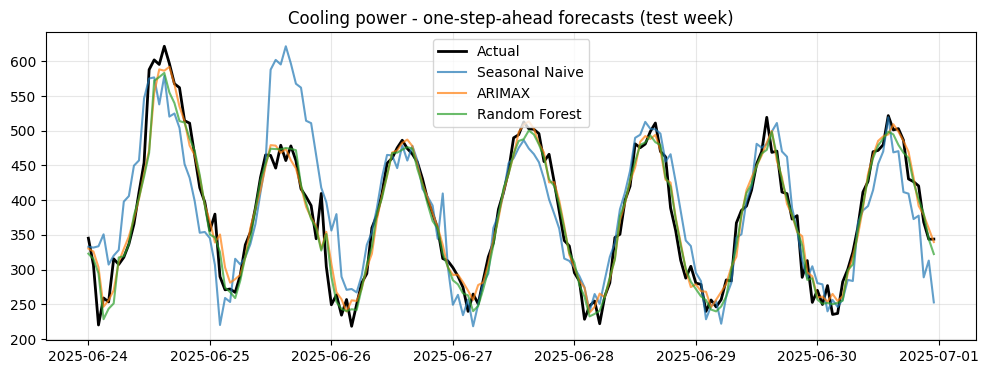

In [16]:
# [LAB REQUIREMENT]
fig, ax = plt.subplots()
ax.plot(test["cooling_kw"], "k", linewidth=2, label="Actual")
for name, p in one_step_preds["cooling_kw"].items():
    ax.plot(p, alpha=0.7, label=name)
ax.set_title("Cooling power - one-step-ahead forecasts (test week)")
ax.legend(); plt.show()

**(b) 7-day-ahead forecasts.** The model does not see the actual values during the 7 days (only the outdoor temperature, which is assumed known from a weather forecast).
> **[LAB REQUIREMENT]**

== 7-day-ahead: cooling_kw ==
                  MAE   RMSE  MAPE %
ARIMAX          23.39  35.24    6.51
Random Forest   25.66  39.48    6.62
Seasonal Naive  62.72  69.68   18.06



== 7-day-ahead: it_kw ==
                   MAE    RMSE  MAPE %
Random Forest    69.80  132.42    3.88
ARIMAX          183.51  197.19   11.54
Seasonal Naive  358.53  381.42   22.89



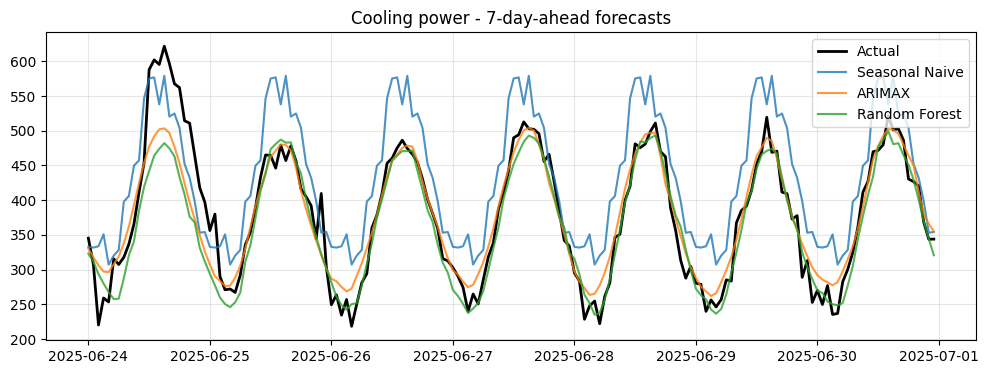

In [17]:
# [LAB REQUIREMENT]
multi_fc, sarimax_ci, multi_table = {}, {}, {}

for tgt in TARGETS:
    fc = {}
    fc["Seasonal Naive"] = pd.Series(np.tile(train[tgt].values[-24:], H // 24)[:H], index=test.index)
    sf = sarimax_res[tgt].get_forecast(steps=H, exog=make_exog(test))
    fc["ARIMAX"] = sf.predicted_mean
    sarimax_ci[tgt] = sf.conf_int(alpha=0.05)
    fc["Random Forest"] = rf_recursive_forecast(rf_models[tgt], rf_cols[tgt], train[tgt], test)
    multi_fc[tgt] = fc
    tbl = pd.DataFrame({k: metrics(test[tgt], v) for k, v in fc.items()}).T
    multi_table[tgt] = tbl.sort_values("RMSE")
    print(f"== 7-day-ahead: {tgt} ==")
    print(multi_table[tgt].round(2))
    print()

fig, ax = plt.subplots()
ax.plot(test["cooling_kw"], "k", linewidth=2, label="Actual")
for name, p in multi_fc["cooling_kw"].items():
    ax.plot(p, alpha=0.8, label=name)
ax.set_title("Cooling power - 7-day-ahead forecasts")
ax.legend(); plt.show()

**(c) Residual analysis** for the best one-step model of cooling power. Left: the size of the errors. Right: whether the errors are still correlated (a pattern the model did not catch).
> **[LAB REQUIREMENT]**

Best model: Random Forest | residual mean: 4.82 | std: 22.22
Ljung-Box p-value (24 lags): 0.62 -> no clear remaining pattern


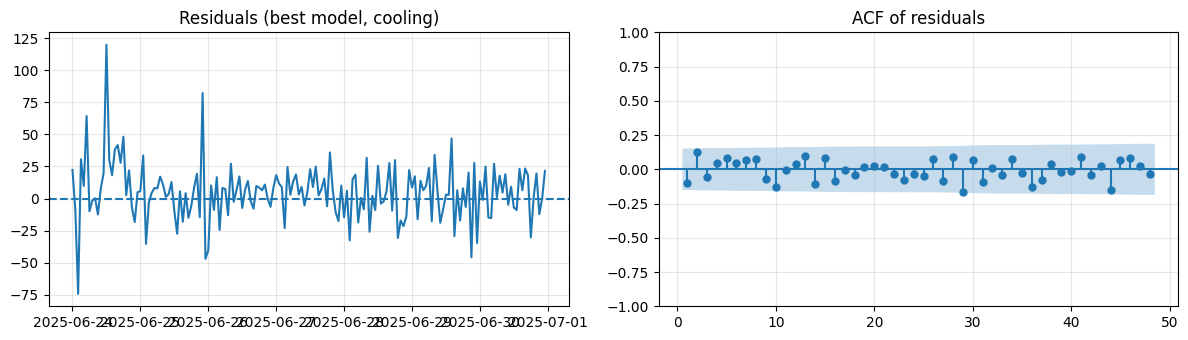

In [18]:
# [LAB REQUIREMENT]
best_cool = one_step_best["cooling_kw"]
res_best = test["cooling_kw"] - one_step_preds["cooling_kw"][best_cool]
print("Best model:", best_cool, "| residual mean:", round(res_best.mean(), 2), "| std:", round(res_best.std(), 2))

lb = acorr_ljungbox(res_best, lags=[24], return_df=True)
print("Ljung-Box p-value (24 lags):", round(lb["lb_pvalue"].iloc[0], 4),
      "-> remaining pattern" if lb["lb_pvalue"].iloc[0] < 0.05 else "-> no clear remaining pattern")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(res_best); ax[0].axhline(0, ls="--"); ax[0].set_title("Residuals (best model, cooling)")
plot_acf(res_best, lags=48, zero=False, ax=ax[1]); ax[1].set_title("ACF of residuals")
plt.tight_layout(); plt.show()

## 11. Student extensions

**Prediction intervals.** The ARIMAX model gives a 95% interval for each forecast hour. We check how often the actual value falls inside the interval (coverage should be close to 95%).
> **[STUDENT IMPROVEMENT]**

95% interval coverage on test week: 92.3 %


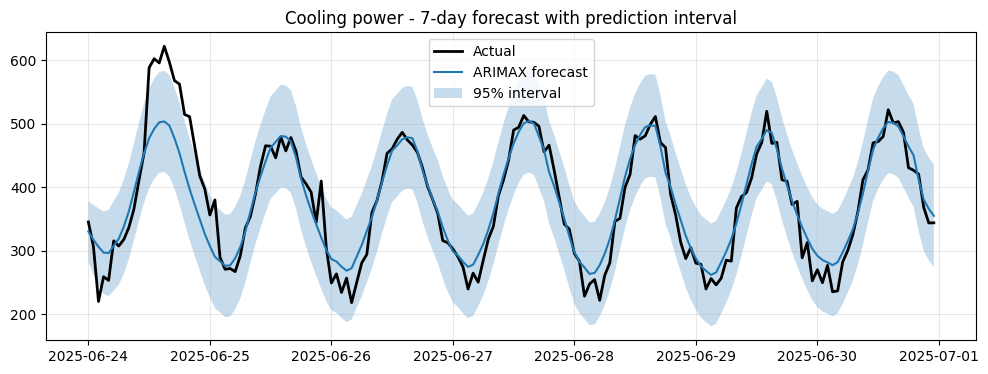

In [19]:
# [STUDENT IMPROVEMENT]
ci = sarimax_ci["cooling_kw"]
lower, upper = ci.iloc[:, 0].values, ci.iloc[:, 1].values
inside = (test["cooling_kw"].values >= lower) & (test["cooling_kw"].values <= upper)
print("95% interval coverage on test week:", round(inside.mean() * 100, 1), "%")

fig, ax = plt.subplots()
ax.plot(test["cooling_kw"], "k", linewidth=2, label="Actual")
ax.plot(multi_fc["cooling_kw"]["ARIMAX"], label="ARIMAX forecast")
ax.fill_between(test.index, lower, upper, alpha=0.25, label="95% interval")
ax.set_title("Cooling power - 7-day forecast with prediction interval")
ax.legend(); plt.show()

**PUE forecast.** PUE = 1 + overhead ratio + cooling / IT. The overhead ratio is estimated from the training data, then PUE is forecast from the best IT and cooling forecasts.
> **[STUDENT IMPROVEMENT]**

Estimated overhead ratio: 0.05
PUE 7-day forecast metrics:
MAE       0.0110
RMSE      0.0131
MAPE %    0.8633
dtype: float64


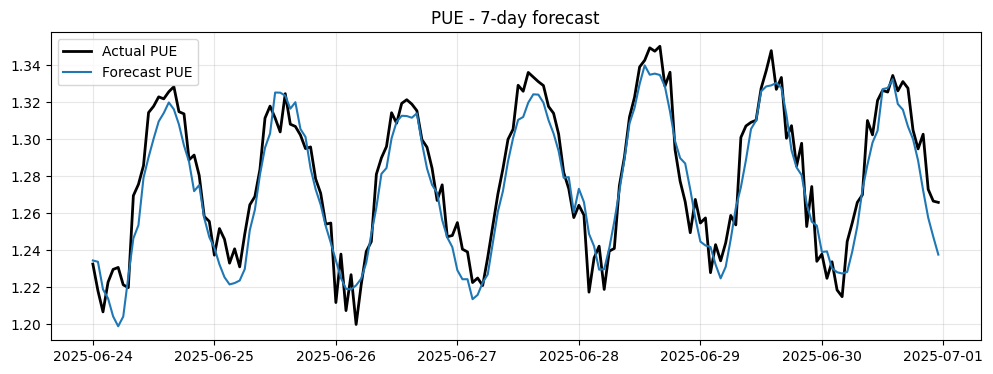

In [20]:
# [STUDENT IMPROVEMENT]
overhead_ratio = ((df["total_kw"] - df["it_kw"] - df["cooling_kw"]) / df["it_kw"]).loc[train.index].mean()
print("Estimated overhead ratio:", round(overhead_ratio, 4))

best_it = one_step_best["it_kw"]
it_fc = multi_fc["it_kw"][best_it]
cool_fc = multi_fc["cooling_kw"][best_cool]
pue_fc = 1 + overhead_ratio + cool_fc / it_fc
pue_actual = test["pue"]

print("PUE 7-day forecast metrics:")
print(pd.Series(metrics(pue_actual, pue_fc)).round(4))

fig, ax = plt.subplots()
ax.plot(pue_actual, "k", linewidth=2, label="Actual PUE")
ax.plot(pue_fc, label="Forecast PUE")
ax.set_title("PUE - 7-day forecast")
ax.legend(); plt.show()

**What-if scenario: +20% IT load (more AI GPU racks).** Cooling is modelled as a linear function of IT load and of the heat above 18 C. The coefficients are estimated on the training data. We then add 20% IT load and check the extra cooling and the PUE change. Note: this simple model has no fixed losses, so PUE stays almost flat when IT load grows; in a real facility PUE usually improves at higher utilisation because fixed losses are spread over more IT load.
> **[STUDENT IMPROVEMENT]**

Coefficients: {'IT load': np.float64(0.1398), 'IT x heat above 18C': np.float64(0.007)}
Average extra cooling in the scenario: 75.9 kW
Average PUE: base 1.280 -> scenario 1.280
Average cooling: base 379.7 kW -> scenario 455.6 kW


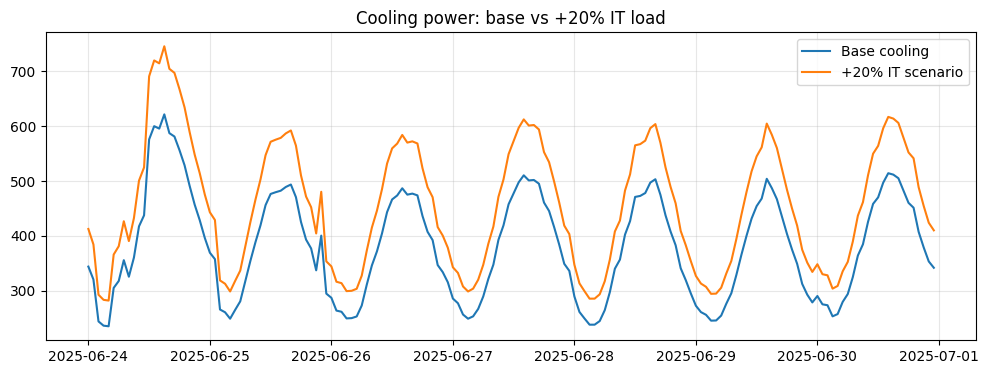

In [21]:
# [STUDENT IMPROVEMENT]
def cooling_design(d):
    T = d["temp_ema3"]
    return pd.DataFrame({
        "it": d["it_kw"],
        "it_x_heat_above_18C": d["it_kw"] * np.clip(T - 18, 0, None),
    }, index=d.index)


cool_lr = LinearRegression(fit_intercept=False).fit(cooling_design(train), train["cooling_kw"])
print("Coefficients:", dict(zip(["IT load", "IT x heat above 18C"], cool_lr.coef_.round(4))))

base_X = cooling_design(test)
scn_X = base_X * 1.2                       # +20% IT load scales both features
cool_base = cool_lr.predict(base_X)
cool_scn = cool_lr.predict(scn_X)
it_scn = test["it_kw"] * 1.2

pue_base = 1 + overhead_ratio + cool_base / test["it_kw"]
pue_scn = 1 + overhead_ratio + cool_scn / it_scn

print(f"Average extra cooling in the scenario: {np.mean(cool_scn - cool_base):.1f} kW")
print(f"Average PUE: base {pue_base.mean():.3f} -> scenario {pue_scn.mean():.3f}")
print(f"Average cooling: base {cool_base.mean():.1f} kW -> scenario {cool_scn.mean():.1f} kW")

fig, ax = plt.subplots()
ax.plot(test.index, cool_base, label="Base cooling")
ax.plot(test.index, cool_scn, label="+20% IT scenario")
ax.set_title("Cooling power: base vs +20% IT load")
ax.legend(); plt.show()

**Cooling capacity alert.** The capacity limit is set to the 95th percentile of cooling power in the training data. We count the hours above the limit in the actual data, the forecast and the scenario.
> **[STUDENT IMPROVEMENT]**

In [22]:
# [STUDENT IMPROVEMENT]
capacity_kw = np.percentile(train["cooling_kw"], 95)
print("Cooling capacity limit (95th percentile of training data):", round(capacity_kw, 1), "kW")

summary_counts = {
    "Actual hours above limit": int((test["cooling_kw"] > capacity_kw).sum()),
    "Forecast hours above limit (best model)": int((cool_fc > capacity_kw).sum()),
    "Scenario hours above limit (+20% IT)": int((cool_scn > capacity_kw).sum()),
}
print(summary_counts)
summary = pd.Series(summary_counts, name="Hours above capacity (of 168)")
summary

Cooling capacity limit (95th percentile of training data): 478.9 kW
{'Actual hours above limit': 27, 'Forecast hours above limit (best model)': 17, 'Scenario hours above limit (+20% IT)': 74}


Actual hours above limit                   27
Forecast hours above limit (best model)    17
Scenario hours above limit (+20% IT)       74
Name: Hours above capacity (of 168), dtype: int64

## 12. Conclusions
> **[LAB REQUIREMENT]**

**Summary of results (test week: 24-30 June 2025, late-summer heat)**

- **One-step-ahead (cooling):** Random Forest has the lowest RMSE (22.7 kW), slightly better than ARIMAX (24.0 kW), and about 56% better than the Seasonal Naive baseline (51.2 kW). This matches the lab finding that the ML model is somewhat better than the naive model.
- **One-step-ahead (IT load):** Random Forest again performs best (RMSE 81.5 kW vs 85.7 kW for ARIMAX and 164.0 kW for Seasonal Naive).
- **7-day-ahead:** the picture changes. ARIMAX is best for cooling (RMSE 35.2 kW vs 39.5 kW for Random Forest), while Random Forest is clearly best for IT load (RMSE 132 kW vs 197 kW for ARIMAX). Recursive Random Forest errors accumulate less than expected for IT load, but the simple ARIMAX with Fourier terms is more robust for cooling.
- **Residuals:** the best one-step model has near-zero mean error (4.8 kW) and no remaining autocorrelation (Ljung-Box p = 0.62), so the simple patterns were captured.
- **Uncertainty:** the 95% ARIMAX interval covered 92.3% of the actual values, close to the nominal 95%.
- **PUE:** the 7-day PUE forecast has MAE 0.011 and MAPE 0.86%, which is accurate enough for operational planning.
- **What-if (+20% IT load):** average cooling rises by about 76 kW (from 380 kW to 456 kW). In this linear model PUE stays flat at 1.28, because fixed losses are not modelled.
- **Capacity alert:** with a limit at the 95th percentile of training cooling (479 kW), the actual test week had 27 hours above the limit, the forecast flagged 17 (it under-predicts the peaks), and the +20% IT scenario would give 74 hours. Extra GPU capacity therefore needs cooling upgrades before it is installed.

**Limitations**
- IT load and cooling are simulated (the outdoor temperature is real). The conclusions show the method works, but real facility data would be needed for production use.
- The evaluation uses one 7-day test window and one data split. A rolling-origin evaluation over several windows would give a more reliable comparison.
- Seasonality in ARIMAX is handled with Fourier terms instead of a full seasonal SARIMA, because the full version ran out of memory in the notebook kernel.
- The cooling scenario model is linear and has no fixed losses, so it shows the absolute cooling increase but not the PUE improvement expected at higher utilisation.